# 00 — Environment and public data access

**Objective:** Check Python package versions and verify access to publicly hosted IBL session metadata.

This notebook does not download raw electrophysiology data or analyze biological outcomes.


In [1]:
%pip -q install one-api numpy pandas scipy matplotlib h5py openpyxl


In [2]:
import sys
import numpy as np
import pandas as pd
import scipy
import matplotlib
from one.api import ONE

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)


Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
SciPy: 1.16.3
Matplotlib: 3.10.0


## Connect to public IBL ONE

The publicly documented OpenAlyx endpoint is used here. The notebook does not store private credentials. Authentication details and access policies may change; consult the official ONE documentation if the connection fails.


In [3]:
one = ONE(
    base_url="https://openalyx.internationalbrainlab.org",
    username="intbrainlab",
    password="international",
    silent=True,
)
print("ONE initialized:", one.alyx.base_url)


ONE initialized: https://openalyx.internationalbrainlab.org


## Inspect a study session after mapping its subject/date

The original study's behavior-list spreadsheets identify subjects and dates. Map those entries to session EIDs before requesting datasets. Do not assume that the first search result is the correct session.


In [4]:
# Replace only after verifying subject and session date against the study metadata.
subject = "NYU-08"
session_date = "2019-10-08" # Format: YYYY-MM-DD

if subject and session_date:
    eids = one.search(subject=subject, date_range=[session_date, session_date])
    print(f"Candidate sessions: {len(eids)}")
    for eid in eids:
        print(eid, one.eid2ref(eid))
else:
    print("Session selection is intentionally deferred until subject/date validation.")


/usr/local/lib/python3.13/dist-packages/one/webclient.py:1053: RuntimeWarning: The shared public account will be retired soon. Register your own account at https://openalyx.internationalbrainlab.org/signup
  emit(message)


Candidate sessions: 1
5e44fd2b-2621-41dc-b9d7-7612dc3b676d {'subject': 'NYU-08', 'date': datetime.date(2019, 10, 8), 'sequence': 2}


In [5]:

# Inspect available datasets without downloading them.
eid = eids[0]

datasets = one.list_datasets(eid, details=False)

print("Session EID:", eid)
print("Number of datasets:", len(datasets))

for dataset in datasets:
    print(dataset)


Session EID: 5e44fd2b-2621-41dc-b9d7-7612dc3b676d
Number of datasets: 5
alf/_ibl_trials.goCueTrigger_times.npy
alf/_ibl_trials.intervals.npy
alf/_ibl_trials.stimOffTrigger_times.npy
alf/_ibl_trials.stimOff_times.npy
alf/_ibl_trials.stimOnTrigger_times.npy


In [7]:
# Find all sessions for the selected subject.
subject = "NYU-08"

subject_sessions = one.search(subject=subject)

print("Total sessions:", len(subject_sessions))

for session_eid in subject_sessions[:15]:
    session_ref = one.eid2ref(session_eid)
    dataset_names = one.list_datasets(session_eid)

    spike_files = [
        name for name in dataset_names
        if "spikes." in name or "clusters." in name
    ]

    print(
        session_ref,
        "| Datasets:", len(dataset_names),
        "| Spike/cluster files:", len(spike_files)
    )


Total sessions: 78
{'subject': 'NYU-08', 'date': datetime.date(2020, 3, 20), 'sequence': 1} | Datasets: 105 | Spike/cluster files: 30
{'subject': 'NYU-08', 'date': datetime.date(2020, 3, 19), 'sequence': 1} | Datasets: 74 | Spike/cluster files: 15
{'subject': 'NYU-08', 'date': datetime.date(2020, 3, 18), 'sequence': 1} | Datasets: 76 | Spike/cluster files: 15
{'subject': 'NYU-08', 'date': datetime.date(2020, 3, 13), 'sequence': 1} | Datasets: 10 | Spike/cluster files: 0
{'subject': 'NYU-08', 'date': datetime.date(2020, 3, 11), 'sequence': 1} | Datasets: 10 | Spike/cluster files: 0
{'subject': 'NYU-08', 'date': datetime.date(2020, 3, 2), 'sequence': 1} | Datasets: 10 | Spike/cluster files: 0
{'subject': 'NYU-08', 'date': datetime.date(2020, 2, 27), 'sequence': 1} | Datasets: 10 | Spike/cluster files: 0
{'subject': 'NYU-08', 'date': datetime.date(2020, 2, 26), 'sequence': 2} | Datasets: 10 | Spike/cluster files: 0
{'subject': 'NYU-08', 'date': datetime.date(2020, 2, 24), 'sequence': 1} |

In [8]:
# Select the recording session from March 20, 2020.
target_date = "2020-03-20"

matching_sessions = [
    eid for eid in subject_sessions
    if one.eid2ref(eid)["date"].isoformat() == target_date
]

print("Matching sessions:", len(matching_sessions))

for eid in matching_sessions:
    print("Session:", eid)

    datasets = one.list_datasets(eid)

    for name in datasets:
        if any(
            keyword in name.lower()
            for keyword in ["spikes.", "clusters.", "channels.", "trials."]
        ):
            print(name)


Matching sessions: 1
Session: cccee322-3163-44bb-9b4b-22083e96e09f
alf/_ibl_trials.goCueTrigger_times.npy
alf/_ibl_trials.intervals_bpod.npy
alf/_ibl_trials.quiescencePeriod.npy
alf/_ibl_trials.stimOffTrigger_times.npy
alf/_ibl_trials.stimOff_times.npy
alf/_ibl_trials.stimOnTrigger_times.npy
alf/_ibl_trials.table.pqt
alf/probe00/_phy_spikes_subset.channels.npy
alf/probe00/_phy_spikes_subset.spikes.npy
alf/probe00/channels.brainLocationIds_ccf_2017.npy
alf/probe00/channels.localCoordinates.npy
alf/probe00/channels.mlapdv.npy
alf/probe00/channels.rawInd.npy
alf/probe00/clusters.amps.npy
alf/probe00/clusters.channels.npy
alf/probe00/clusters.depths.npy
alf/probe00/clusters.metrics.pqt
alf/probe00/clusters.peakToTrough.npy
alf/probe00/clusters.uuids.csv
alf/probe00/clusters.waveforms.npy
alf/probe00/clusters.waveformsChannels.npy
alf/probe00/spikes.amps.npy
alf/probe00/spikes.clusters.npy
alf/probe00/spikes.depths.npy
alf/probe00/spikes.samples.npy
alf/probe00/spikes.templates.npy
alf/prob

In [9]:
# Load spike times and cluster assignments.
eid = "cccee322-3163-44bb-9b4b-22083e96e09f"

spike_times = one.load_dataset(
    eid,
    "spikes.times.npy",
    collection="alf/probe00"
)

spike_clusters = one.load_dataset(
    eid,
    "spikes.clusters.npy",
    collection="alf/probe00"
)

# Basic dataset inspection.
print("Total spikes:", len(spike_times))
print("Unique cluster IDs:", len(np.unique(spike_clusters)))
print("Recording time range (s):", spike_times.min(), spike_times.max())
print("Array lengths match:", len(spike_times) == len(spike_clusters))


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-08/2020-03-20/001/alf/probe00/spikes.times.npy: 100%|██████████| 23.4M/23.4M [00:00<00:00, 39.2MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/NYU-08/2020-03-20/001/alf/probe00/spikes.clusters.npy: 100%|██████████| 11.7M/11.7M [00:00<00:00, 23.8MB/s]

Total spikes: 2927983
Unique cluster IDs: 148
Recording time range (s): 0.014131890799512152 5017.46553184058
Array lengths match: True


Selected cluster: 31
Number of spikes: 169928


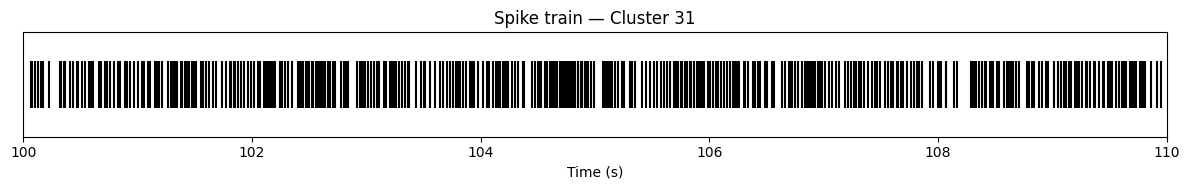

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Select one cluster for an initial visualization.
cluster_ids, spike_counts = np.unique(
    spike_clusters,
    return_counts=True
)

cluster_id = cluster_ids[np.argmax(spike_counts)]

# Extract spike times belonging to the selected cluster.
neuron_spikes = spike_times[spike_clusters == cluster_id]

print("Selected cluster:", cluster_id)
print("Number of spikes:", len(neuron_spikes))

# Visualize a 10-second segment of the spike train.
start_time = 100
end_time = 110

segment = neuron_spikes[
    (neuron_spikes >= start_time) &
    (neuron_spikes < end_time)
]

fig, ax = plt.subplots(figsize=(12, 2))

ax.eventplot(
    segment,
    orientation="horizontal",
    colors="black",
    lineoffsets=1,
    linelengths=0.7
)

ax.set_xlim(start_time, end_time)
ax.set_yticks([])
ax.set_xlabel("Time (s)")
ax.set_title(f"Spike train — Cluster {cluster_id}")
plt.tight_layout()
plt.show()


Cluster ID: 31
Mean firing rate: 33.87 Hz
Mean ISI: 29.53 ms
CV of ISI: 0.646
Mean CV2: 0.533


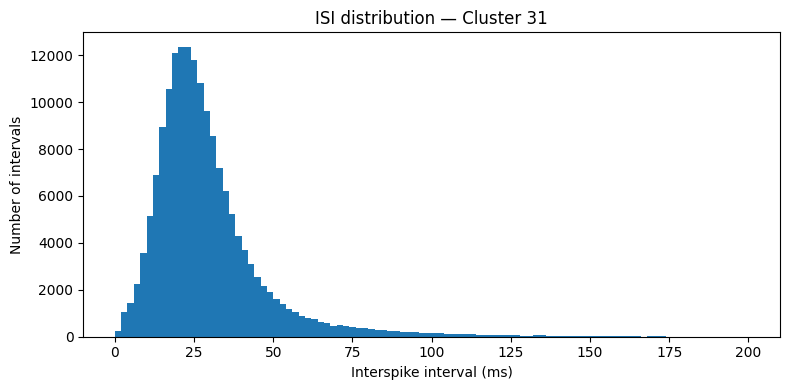

In [14]:
# Calculate interspike intervals for the selected cluster.
isi = np.diff(neuron_spikes)

# Calculate firing statistics.
duration = spike_times.max() - spike_times.min()
mean_fr = len(neuron_spikes) / duration
mean_isi = np.mean(isi) * 1000
cv_isi = np.std(isi) / np.mean(isi)

# Calculate local firing irregularity (CV2).
cv2 = 2 * np.abs(np.diff(isi)) / (isi[:-1] + isi[1:])

print(f"Cluster ID: {cluster_id}")
print(f"Mean firing rate: {mean_fr:.2f} Hz")
print(f"Mean ISI: {mean_isi:.2f} ms")
print(f"CV of ISI: {cv_isi:.3f}")
print(f"Mean CV2: {np.mean(cv2):.3f}")

# Plot the ISI distribution.
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(isi * 1000, bins=np.linspace(0, 200, 101))

ax.set_xlabel("Interspike interval (ms)")
ax.set_ylabel("Number of intervals")
ax.set_title(f"ISI distribution — Cluster {cluster_id}")

plt.tight_layout()
plt.show()


In [16]:
# Calculate spike train metrics for all clusters.
recording_duration = spike_times.max() - spike_times.min()

results = []

for cid in np.unique(spike_clusters):

    # Extract spikes belonging to the current cluster.
    neuron_times = spike_times[spike_clusters == cid]
    neuron_times = np.sort(neuron_times)

    # Calculate interspike intervals.
    isi = np.diff(neuron_times)

    if len(isi) < 2:
        continue

    # Calculate firing rate and ISI statistics.
    firing_rate = len(neuron_times) / recording_duration
    mean_isi_ms = np.mean(isi) * 1000
    cv_isi = np.std(isi) / np.mean(isi)

    # Calculate local firing irregularity.
    cv2_values = (
        2 * np.abs(np.diff(isi)) /
        (isi[:-1] + isi[1:])
    )

    mean_cv2 = np.mean(cv2_values)

    results.append({
        "cluster_id": int(cid),
        "spike_count": len(neuron_times),
        "firing_rate_hz": firing_rate,
        "mean_isi_ms": mean_isi_ms,
        "cv_isi": cv_isi,
        "cv2": mean_cv2
    })

metrics_df = pd.DataFrame(results)

print("Analyzed clusters:", len(metrics_df))
display(metrics_df.head(10))


Analyzed clusters: 148


,cluster_id,spike_count,firing_rate_hz,mean_isi_ms,cv_isi,cv2
0,0,13773,2.745019,364.235763,4.617665,1.104463
1,1,69091,13.770138,72.606796,7.088383,0.958529
2,2,56446,11.249935,88.871625,6.999153,0.921892
3,3,113,0.022521,42243.269234,5.136997,1.018756
4,4,34162,6.808636,146.856322,5.190673,1.034942
5,5,33673,6.711176,148.987527,5.856849,0.993073
6,6,17312,3.450357,289.766372,1.446384,1.027590
7,7,16108,3.210395,311.481192,1.197147,0.943377
8,8,17630,3.513736,284.581249,3.481762,1.089533
9,9,15130,3.015475,331.566184,3.834386,1.071320


Population summary:


,firing_rate_hz,cv_isi,cv2
count,148.000,148.000,148.000
mean,3.943,3.232,1.077
std,4.373,1.944,0.140
min,0.005,0.646,0.533
25%,1.416,1.560,1.001
50%,2.985,3.220,1.083
75%,5.148,4.404,1.164
max,33.867,13.126,1.479


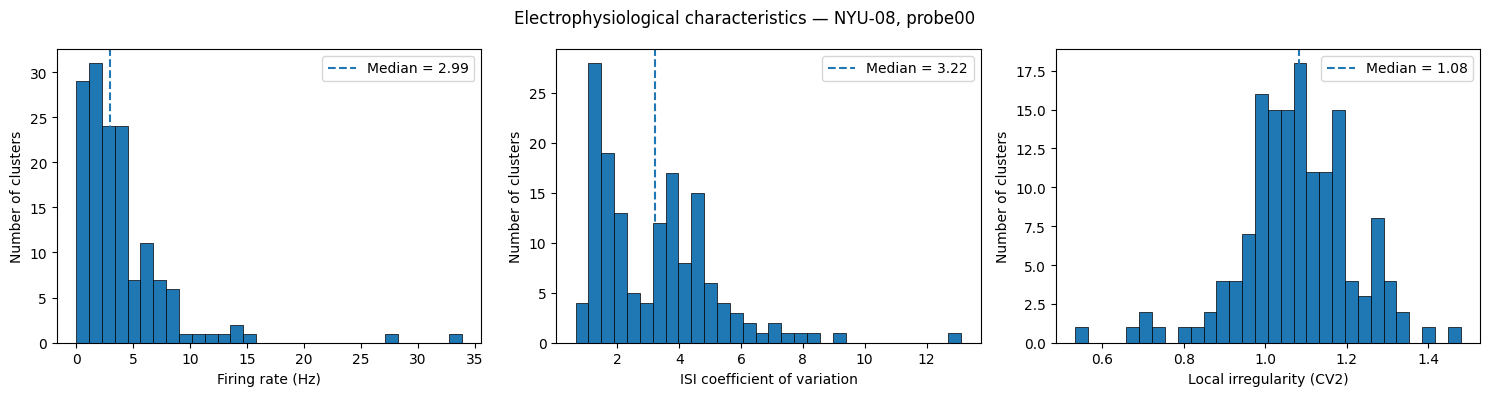

In [17]:

import numpy as np
import matplotlib.pyplot as plt

# Summarize the population-level electrophysiological metrics.
columns = ["firing_rate_hz", "cv_isi", "cv2"]

print("Population summary:")
display(metrics_df[columns].describe().round(3))

# Visualize the distributions of the three metrics.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

labels = [
    "Firing rate (Hz)",
    "ISI coefficient of variation",
    "Local irregularity (CV2)"
]

for ax, column, label in zip(axes, columns, labels):
    values = metrics_df[column].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    ax.hist(values, bins=30, edgecolor="black", linewidth=0.5)
    ax.axvline(
        values.median(),
        linestyle="--",
        label=f"Median = {values.median():.2f}"
    )

    ax.set_xlabel(label)
    ax.set_ylabel("Number of clusters")
    ax.legend()

plt.suptitle(
    "Electrophysiological characteristics — NYU-08, probe00"
)
plt.tight_layout()
plt.show()


## Reproducibility checklist

- [ ] Confirm one session's subject, date, probe, and genotype.
- [ ] List available spike/cluster and trial datasets before download.
- [ ] Record session EID, download source, processing version, and quality-control rules.
- [ ] Freeze analysis definitions before genotype comparisons.
- [ ] Save only code and lightweight metadata to GitHub.


In [11]:

from google.colab import drive

drive.mount("/content/drive")


Mounted at /content/drive


In [12]:
from pathlib import Path

# Search the mounted Google Drive for the expected Excel file.
drive_root = Path("/content/drive/MyDrive")

matches = list(drive_root.rglob("behavior_list_NYU.xlsx"))

print("Files found:", len(matches))

for path in matches:
    print(path)


Files found: 1
/content/drive/MyDrive/Jan/Reanalysis/Behaviour/behavior_list_NYU.xlsx


In [13]:

# Path to the original control-group session list
file_path = "/content/drive/MyDrive/Jan/Reanalysis/Behaviour/behavior_list_NYU.xlsx"

# Read the spreadsheet without treating the first row as a header
df = pd.read_excel(file_path, header=None)

# Assign temporary column names
df.columns = [
    "subject",
    "column_2",
    "session_date",
    "column_4",
    "column_5"
]

# Inspect the corrected dataset
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head(10))


Dataset shape: (823, 5)
Column names: ['subject', 'column_2', 'session_date', 'column_4', 'column_5']


,subject,column_2,session_date,column_4,column_5
0,NYU-08,NaN,2019-10-08/,2019-10-09 07:04:00,-
1,NYU-08,NaN,2019-10-09/,2019-10-10 07:02:00,-
2,NYU-08,NaN,2019-10-10/,2019-10-12 07:03:00,-
3,NYU-08,NaN,2019-10-14/,2019-10-15 07:01:00,-
4,NYU-08,NaN,2019-10-15/,2019-10-16 07:03:00,-
5,NYU-08,NaN,2019-10-16/,2019-10-17 07:03:00,-
6,NYU-08,NaN,2019-10-17/,2019-10-23 07:05:00,-
7,NYU-08,NaN,2019-10-18/,2019-10-23 07:05:00,-
8,NYU-08,NaN,2019-10-21/,2019-10-23 07:05:00,-
9,NYU-08,NaN,2019-10-22/,2019-10-23 07:05:00,-
